In [1]:
pip install pandas xgboost matplotlib numpy scikit-learn

  Using cached pandas-3.0.6-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached xgboost-3.4.1-py3-none-manylinux_2_28_x86_64.whl.metadata (2.0 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached nvidia_nccl_cu13-2.32.3-py3-none-manylinux_2_27_x86_64.whl.metadata (2.1 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (137 kB)
  Using

In [9]:
pip install lightgbm joblib

  Using cached lightgbm-4.7.0-py3-none-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
Using cached lightgbm-4.7.0-py3-none-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (3.5 MB)
Note: you may need to restart the kernel to use updated packages.


In [10]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns          # optional, only for EDA plots
import lightgbm as lgb
import joblib
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve, classification_report,
                             confusion_matrix)

## Hypertension Model

In [11]:
DATA = "/run/media/pravesh/New Volume/Promethius-26/datasets"

train = pd.read_csv(os.path.join(DATA, "hypertension_train.csv"))
ext   = pd.read_csv(os.path.join(DATA, "hypertension_external.csv"))

TARGET = "htn"
FEATURES = ["age", "sex_female", "bmi", "waist_cm", "waist_to_height",
            "smoking_status", "alcohol_days_per_year", "alcohol_drinks_per_day",
            "leisure_mvpa_min_wk", "sedentary_min_day",
            "known_diabetes", "borderline_diabetes", "sleep_hours"]
KEEP = ["seqn", "weight", "ref_undiagnosed_htn"]   # evaluation only, never features

# plausible ranges -> anything outside becomes NaN
LIMITS = {
    "age": (18, 80), "bmi": (13, 70), "waist_cm": (50, 180), "waist_to_height": (0.3, 1.0),
    "alcohol_days_per_year": (0, 365), "alcohol_drinks_per_day": (0, 15),
    "leisure_mvpa_min_wk": (0, 3000), "sedentary_min_day": (0, 1200), "sleep_hours": (3, 13),
}

def clean(df, name):
    df = df[KEEP + FEATURES + [TARGET]].copy()
    n0 = len(df)
    df = df.drop_duplicates(subset="seqn")
    df = df[df[TARGET].isin([0, 1])]
    fixed = {}
    for col, (lo, hi) in LIMITS.items():
        bad = df[col].notna() & ~df[col].between(lo, hi)
        if bad.any():
            fixed[col] = int(bad.sum())
            df.loc[bad, col] = np.nan
    print(f"{name}: {n0:,} -> {len(df):,} rows | out-of-range set to NaN: {fixed or 'none'}")
    return df.reset_index(drop=True)

train = clean(train, "train (2017–20)")
ext   = clean(ext,   "external (2021–23)")

miss = pd.DataFrame({"train_%": train[FEATURES].isna().mean() * 100,
                     "external_%": ext[FEATURES].isna().mean() * 100}).round(1)
print("\nMissing values (%):"); print(miss[miss.max(axis=1) > 0])
print(f"\nLabel balance  train: {train[TARGET].mean():.1%}   external: {ext[TARGET].mean():.1%}")
print(train[FEATURES].describe().T[["mean", "min", "50%", "max"]].round(2))

train (2017–20): 7,948 -> 7,948 rows | out-of-range set to NaN: {'bmi': 5, 'waist_cm': 1, 'waist_to_height': 8, 'leisure_mvpa_min_wk': 21, 'sedentary_min_day': 2, 'sleep_hours': 59}
external (2021–23): 6,084 -> 6,084 rows | out-of-range set to NaN: {'bmi': 1, 'waist_cm': 1, 'waist_to_height': 5, 'leisure_mvpa_min_wk': 70, 'sedentary_min_day': 3, 'sleep_hours': 50}

Missing values (%):
                        train_%  external_%
bmi                         1.0         1.0
waist_cm                    3.0         3.3
waist_to_height             3.2         3.5
smoking_status              0.1         0.1
alcohol_days_per_year       3.7        11.9
alcohol_drinks_per_day      3.8        12.3
leisure_mvpa_min_wk         0.4         2.4
sedentary_min_day           0.7         0.8
sleep_hours                 1.6         1.8

Label balance  train: 40.0%   external: 39.1%
                          mean    min     50%      max
age                      49.58  18.00   51.00    80.00
sex_female     

               model  AUROC  AUROC_sd  AUPRC  Brier  seconds
HistGradientBoosting 0.8300    0.0121 0.5474 0.1239   0.4083
            LightGBM 0.8286    0.0122 0.5431 0.1248   0.5001
       Random Forest 0.8251    0.0140 0.5402 0.1258   2.3066
 Logistic Regression 0.8214    0.0126 0.5217 0.1269   0.1843
       Decision Tree 0.7993    0.0137 0.4802 0.1320   0.1385

Best: HistGradientBoosting (AUROC 0.830 ± 0.012)
Statistically tied with best (within 1 SD): HistGradientBoosting, LightGBM, Random Forest, Logistic Regression


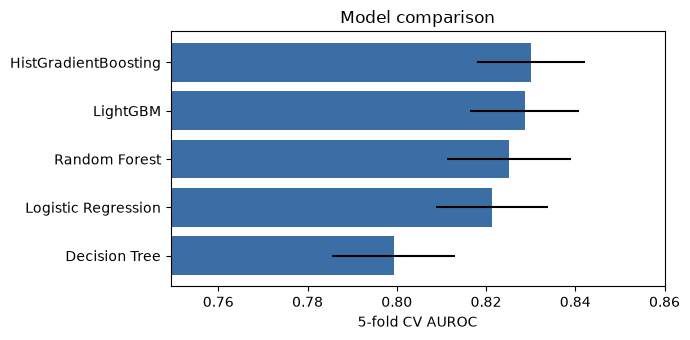

In [21]:
# ===== MODEL COMPARISON — run after the cleaning cell (works for Model 1 or 2)
import time, lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

X, y = train[FEATURES], train[TARGET]       # 2017–20 only; 2021–23 stays untouched

candidates = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                         LogisticRegression(max_iter=2000)),
    "Decision Tree":       make_pipeline(SimpleImputer(strategy="median"),
                                         DecisionTreeClassifier(max_depth=6, min_samples_leaf=40, random_state=42)),
    "Random Forest":       make_pipeline(SimpleImputer(strategy="median"),
                                         RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                                                n_jobs=-1, random_state=42)),
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.05, max_leaf_nodes=15,
                                                           min_samples_leaf=40, random_state=42),
    "LightGBM":            lgb.LGBMClassifier(learning_rate=0.03, n_estimators=300, num_leaves=15,
                                              min_child_samples=40, subsample=0.8, subsample_freq=1,
                                              colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, est in candidates.items():
    t0 = time.time()
    s = cross_validate(est, X, y, cv=cv, scoring=["roc_auc", "average_precision", "neg_brier_score"])
    rows.append({"model": name,
                 "AUROC": s["test_roc_auc"].mean(), "AUROC_sd": s["test_roc_auc"].std(),
                 "AUPRC": s["test_average_precision"].mean(),
                 "Brier": -s["test_neg_brier_score"].mean(),
                 "seconds": time.time() - t0})
res = pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True)
print(res.round(4).to_string(index=False))

best = res.iloc[0]
close = res[res.AUROC >= best.AUROC - best.AUROC_sd]
print(f"\nBest: {best.model} (AUROC {best.AUROC:.3f} ± {best.AUROC_sd:.3f})")
print("Statistically tied with best (within 1 SD):", ", ".join(close.model))

plt.figure(figsize=(7, 3.5))
plt.barh(res.model[::-1], res.AUROC[::-1], xerr=res.AUROC_sd[::-1], color="#3b6ea5")
plt.xlim(max(0.5, res.AUROC.min() - 0.05), min(1, res.AUROC.max() + 0.03))
plt.xlabel("5-fold CV AUROC"); plt.title("Model comparison"); plt.tight_layout(); plt.show()

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
imp, sc = SimpleImputer(strategy="median"), StandardScaler()
X_lr = sc.fit_transform(imp.fit_transform(train[FEATURES]))   # fit on train
X_lr_ext = sc.transform(imp.transform(ext[FEATURES]))         # only transform others

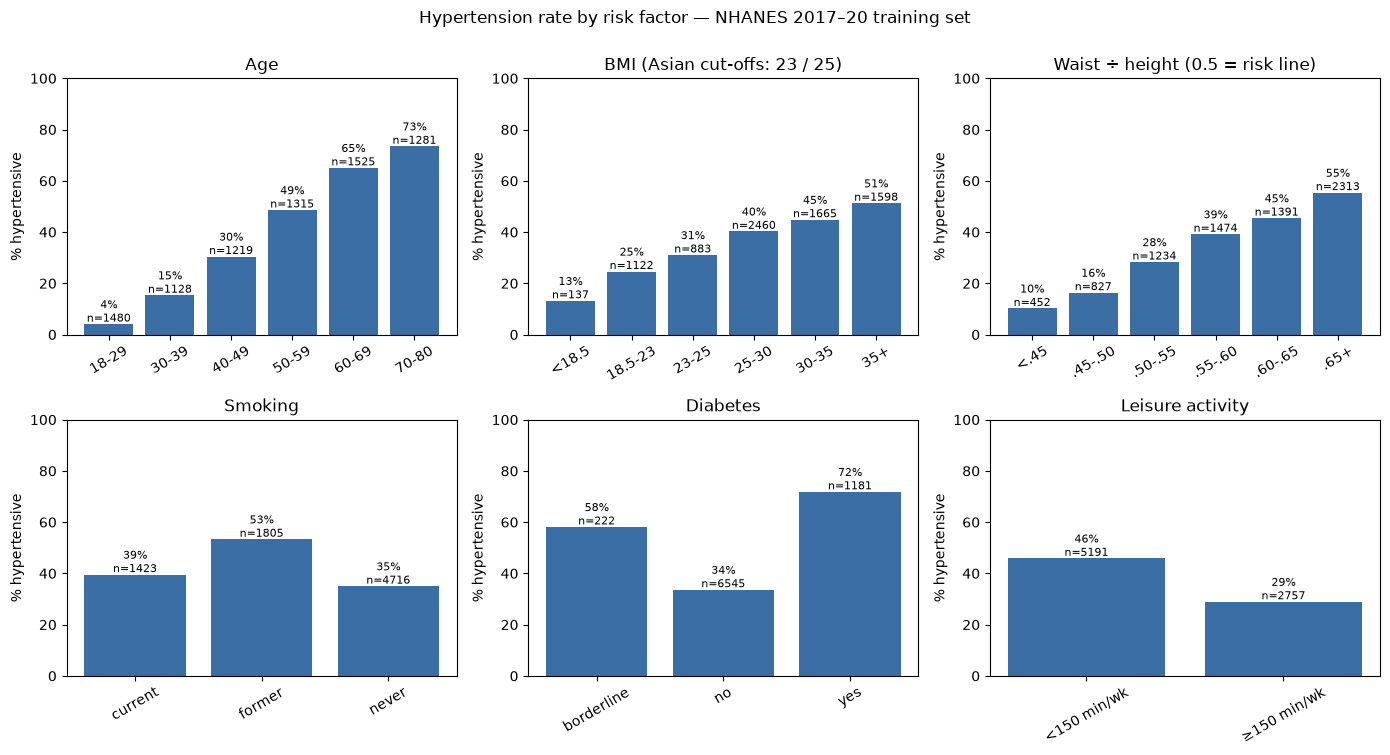

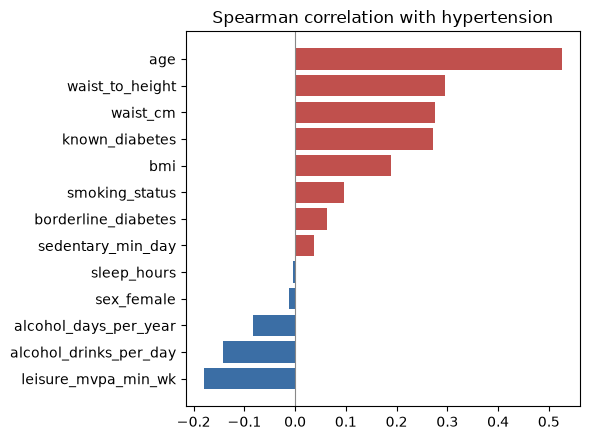

leisure_mvpa_min_wk      -0.180
alcohol_drinks_per_day   -0.142
alcohol_days_per_year    -0.083
sex_female               -0.011
sleep_hours              -0.004
sedentary_min_day         0.038
borderline_diabetes       0.063
smoking_status            0.096
bmi                       0.189
known_diabetes            0.272
waist_cm                  0.276
waist_to_height           0.295
age                       0.526

Train vs external means:
                        train_mean  external_mean  diff_%
age                          49.58          52.56     6.0
sex_female                    0.50           0.54     8.8
bmi                          29.85          29.57    -0.9
waist_cm                    100.51         100.33    -0.2
waist_to_height               0.60           0.60    -0.1
smoking_status                0.59           0.55    -6.9
alcohol_days_per_year        48.33          60.30    24.8
alcohol_drinks_per_day        1.79           1.97    10.1
leisure_mvpa_min_wk         217.02  

In [13]:
# ---- EDA 1: hypertension rate by risk factor
eda = train.copy()
eda["age_band"] = pd.cut(eda["age"], [17, 29, 39, 49, 59, 69, 80], labels=["18-29","30-39","40-49","50-59","60-69","70-80"])
eda["bmi_band"] = pd.cut(eda["bmi"], [0, 18.5, 23, 25, 30, 35, 100], labels=["<18.5","18.5-23","23-25","25-30","30-35","35+"])
eda["wht_band"] = pd.cut(eda["waist_to_height"], [0, 0.45, 0.5, 0.55, 0.6, 0.65, 2], labels=["<.45",".45-.50",".50-.55",".55-.60",".60-.65",".65+"])
eda["smoking"] = eda["smoking_status"].map({0: "never", 1: "former", 2: "current"})
eda["diabetes"] = np.select([eda["known_diabetes"] == 1, eda["borderline_diabetes"] == 1], ["yes", "borderline"], "no")
eda["active_150"] = np.where(eda["leisure_mvpa_min_wk"] >= 150, "≥150 min/wk", "<150 min/wk")

panels = ["age_band", "bmi_band", "wht_band", "smoking", "diabetes", "active_150"]
titles = ["Age", "BMI (Asian cut-offs: 23 / 25)", "Waist ÷ height (0.5 = risk line)", "Smoking", "Diabetes", "Leisure activity"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col, t in zip(axes.flat, panels, titles):
    g = eda.groupby(col, observed=True)[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"] * 100, color="#3b6ea5")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 1, f"{m:.0%}\nn={n}", ha="center", fontsize=8)
    ax.set_title(t); ax.set_ylim(0, 100); ax.set_ylabel("% hypertensive")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Hypertension rate by risk factor — NHANES 2017–20 training set", y=1.0)
plt.tight_layout(); plt.show()

# ---- EDA 2: correlation of each feature with the label
corr = train[FEATURES + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(6, 4.5))
plt.barh(corr.index, corr.values, color=np.where(corr.values > 0, "#c0504d", "#3b6ea5"))
plt.axvline(0, color="#888", lw=0.8); plt.title("Spearman correlation with hypertension")
plt.tight_layout(); plt.show()
print(corr.round(3).to_string())

# ---- EDA 3: drift between train (2017–20) and external (2021–23)
drift = pd.DataFrame({"train_mean": train[FEATURES].mean(), "external_mean": ext[FEATURES].mean()})
drift["diff_%"] = ((drift["external_mean"] - drift["train_mean"]) / drift["train_mean"].abs() * 100).round(1)
print("\nTrain vs external means:"); print(drift.round(2))

In [14]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

SEED = 42

# ---- 1. split 2017–20 into train 60% / valid 20% / internal test 20%
tr, rest = train_test_split(train, test_size=0.4, stratify=train[TARGET], random_state=SEED)
va, te   = train_test_split(rest,  test_size=0.5, stratify=rest[TARGET],  random_state=SEED)
print(f"train {len(tr):,} | valid {len(va):,} | internal test {len(te):,} | external {len(ext):,}")

# ---- 2. monotone constraints: risk can only go UP with these
MONO = {"age": 1, "bmi": 1, "waist_cm": 1, "waist_to_height": 1, "known_diabetes": 1}
params = dict(
    objective="binary", metric="auc",
    learning_rate=0.03, num_leaves=15, min_child_samples=40,
    feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
    monotone_constraints=[MONO.get(f, 0) for f in FEATURES],
    monotone_constraints_method="advanced",
    verbose=-1, seed=SEED,
)

# ---- 3. train with early stopping on the validation split
dtr = lgb.Dataset(tr[FEATURES], tr[TARGET])
dva = lgb.Dataset(va[FEATURES], va[TARGET], reference=dtr)
model = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva], valid_names=["valid"],
                  callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(200)])
print("best iteration:", model.best_iteration)

# ---- 4. isotonic calibration (fit on validation split only)
raw = lambda df: model.predict(df[FEATURES], num_iteration=model.best_iteration)
cal = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(raw(va), va[TARGET])
predict = lambda df: cal.predict(raw(df))

p_va, p_te, p_ext = predict(va), predict(te), predict(ext)
y_va, y_te, y_ext = va[TARGET].values, te[TARGET].values, ext[TARGET].values

for name, y, p in [("internal test", y_te, p_te), ("external test", y_ext, p_ext)]:
    print(f"{name:14s} AUROC {roc_auc_score(y, p):.3f} | Brier {brier_score_loss(y, p):.3f} "
          f"| mean predicted {p.mean():.1%} vs actual {y.mean():.1%}")

train 4,768 | valid 1,590 | internal test 1,590 | external 6,084
[200]	valid's auc: 0.837108
best iteration: 181
internal test  AUROC 0.841 | Brier 0.159 | mean predicted 39.7% vs actual 39.9%
external test  AUROC 0.816 | Brier 0.172 | mean predicted 42.8% vs actual 39.1%


Referral threshold: refer if risk >= 0.31

INTERNAL TEST (2017–20)
  sensitivity 84.9% | specificity 67.6% | PPV 63.6% | NPV 87.1% | AUPRC 0.739
  refers 53% of people  ->  catches 72.1% of the 122 UNDIAGNOSED hypertensives
  weighted AUROC (US population): 0.837
EXTERNAL TEST (2021–23)
  sensitivity 86.8% | specificity 60.9% | PPV 58.7% | NPV 87.7% | AUPRC 0.690
  refers 58% of people  ->  catches 71.9% of the 391 UNDIAGNOSED hypertensives
  weighted AUROC (US population): 0.833

Risk bands — internal:
          people  actual HTN rate  share
band                                    
low          465            0.047  0.292
moderate     364            0.286  0.229
high         761            0.669  0.479

Risk bands — external:
          people  actual HTN rate  share
band                                    
low         1582            0.058  0.260
moderate    1318            0.245  0.217
high        3184            0.617  0.523

AUROC by subgroup:
              internal  external
male

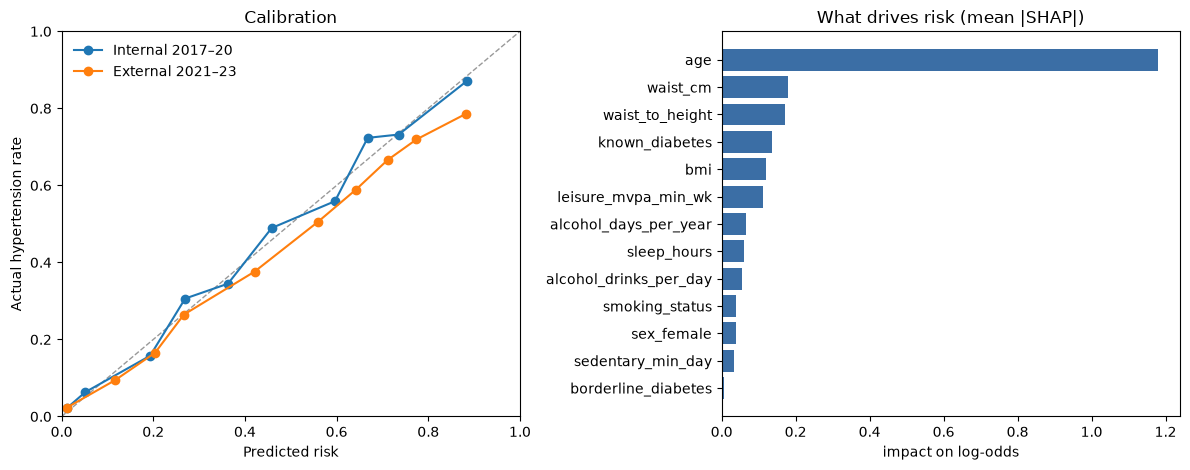


Top drivers: age, waist_cm, waist_to_height, known_diabetes, bmi, leisure_mvpa_min_wk


In [15]:
from sklearn.metrics import roc_curve, average_precision_score

# ---- 1. referral threshold: catch >= 85% of hypertension cases (chosen on VALID only)
fpr, tpr, thr = roc_curve(y_va, p_va)
THRESHOLD = float(thr[np.argmax(tpr >= 0.85)])
print(f"Referral threshold: refer if risk >= {THRESHOLD:.2f}\n")

def report(name, df, y, p):
    flag = p >= THRESHOLD
    tp, fn = (flag & (y == 1)).sum(), (~flag & (y == 1)).sum()
    tn, fp = (~flag & (y == 0)).sum(), (flag & (y == 0)).sum()
    und = df["ref_undiagnosed_htn"].values == 1
    print(f"{name}")
    print(f"  sensitivity {tp/(tp+fn):.1%} | specificity {tn/(tn+fp):.1%} | PPV {tp/(tp+fp):.1%} "
          f"| NPV {tn/(tn+fn):.1%} | AUPRC {average_precision_score(y, p):.3f}")
    print(f"  refers {flag.mean():.0%} of people  ->  catches {flag[und].mean():.1%} of the "
          f"{und.sum()} UNDIAGNOSED hypertensives")
    print(f"  weighted AUROC (US population): {roc_auc_score(y, p, sample_weight=df['weight']):.3f}")

report("INTERNAL TEST (2017–20)", te, y_te, p_te)
report("EXTERNAL TEST (2021–23)", ext, y_ext, p_ext)

# ---- 2. risk bands: does "high" really mean high?
BANDS = [0, 0.20, 0.45, 1.01]; NAMES = ["low", "moderate", "high"]
for name, y, p in [("internal", y_te, p_te), ("external", y_ext, p_ext)]:
    b = pd.cut(p, BANDS, labels=NAMES, right=False)
    t = pd.DataFrame({"band": b, "y": y}).groupby("band", observed=True)["y"].agg(["size", "mean"])
    t.columns = ["people", "actual HTN rate"]; t["share"] = t["people"] / t["people"].sum()
    print(f"\nRisk bands — {name}:"); print(t.round(3))

# ---- 3. fairness: AUROC by subgroup
def subgroups(df, y, p):
    g = {"male": df.sex_female == 0, "female": df.sex_female == 1,
         "18-39": df.age.between(18, 39), "40-59": df.age.between(40, 59), "60+": df.age >= 60,
         "diabetic": df.known_diabetes == 1, "non-diabetic": df.known_diabetes == 0}
    return {k: round(roc_auc_score(y[m.values], p[m.values]), 3) for k, m in g.items()
            if m.sum() > 50 and len(set(y[m.values])) == 2}
print("\nAUROC by subgroup:")
print(pd.DataFrame({"internal": subgroups(te, y_te, p_te), "external": subgroups(ext, y_ext, p_ext)}))

# ---- 4. calibration plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
ax[0].plot([0, 1], [0, 1], "--", color="#999", lw=1)
for name, y, p in [("Internal 2017–20", y_te, p_te), ("External 2021–23", y_ext, p_ext)]:
    d = pd.DataFrame({"p": p, "y": y}); d["bin"] = pd.qcut(d.p, 10, duplicates="drop")
    c = d.groupby("bin", observed=True).mean()
    ax[0].plot(c.p, c.y, "o-", label=name)
ax[0].set(xlabel="Predicted risk", ylabel="Actual hypertension rate", title="Calibration", xlim=(0, 1), ylim=(0, 1))
ax[0].legend(frameon=False)

# ---- 5. what drives predictions (SHAP, built into LightGBM)
contrib = model.predict(te[FEATURES], num_iteration=model.best_iteration, pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=FEATURES).sort_values()
ax[1].barh(imp.index, imp.values, color="#3b6ea5")
ax[1].set(title="What drives risk (mean |SHAP|)", xlabel="impact on log-odds")
plt.tight_layout(); plt.show()
print("\nTop drivers:", ", ".join(imp.index[::-1][:6]))

In [16]:
import joblib, json
OUT = "/run/media/pravesh/New Volume/Promethius-26/models/hypertension"
os.makedirs(OUT, exist_ok=True)

joblib.dump({
    "booster_str": model.model_to_string(num_iteration=model.best_iteration),
    "calibrator": cal,
    "features": FEATURES,
    "bands": [(0.0, 0.20, "low"), (0.20, 0.45, "moderate"), (0.45, 1.01, "high")],
    "threshold": THRESHOLD,
}, os.path.join(OUT, "htn_bundle.joblib"))
model.save_model(os.path.join(OUT, "htn_model.txt"), num_iteration=model.best_iteration)

with open(os.path.join(OUT, "metrics.json"), "w") as f:
    json.dump({"threshold": THRESHOLD,
               "internal_auroc": float(roc_auc_score(y_te, p_te)),
               "external_auroc": float(roc_auc_score(y_ext, p_ext)),
               "features": FEATURES}, f, indent=2)
print("saved:", os.listdir(OUT))

saved: ['htn_bundle.joblib', 'htn_model.txt', 'metrics.json']


## Diabetes 

train (2017–20): 8,070 rows | diabetes 20.5% | undiagnosed 2.9% (237 people)
external (2021–23): 5,779 rows | diabetes 18.7% | undiagnosed 2.2% (128 people)


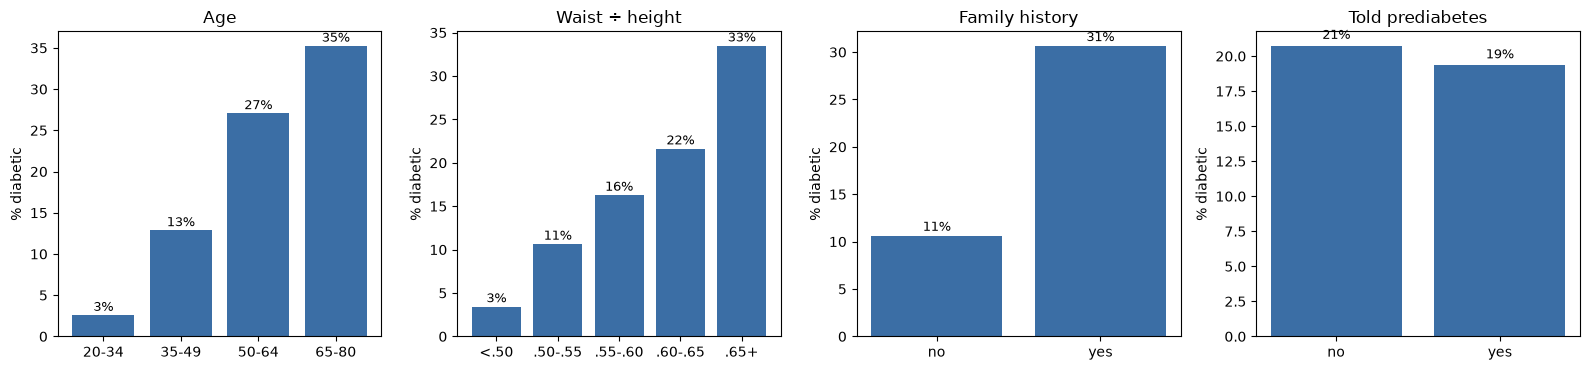

In [17]:
DATA = "/run/media/pravesh/New Volume/Promethius-26/datasets"
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

train = pd.read_csv(os.path.join(DATA, "diabetes_train.csv"))
ext   = pd.read_csv(os.path.join(DATA, "diabetes_external.csv"))

TARGET = "dm"
FEATURES = ["age", "sex_female", "bmi", "waist_cm", "waist_to_height", "family_history_dm",
            "told_prediabetes", "told_hypertension", "smoking_status", "alcohol_days_per_year",
            "leisure_mvpa_min_wk", "sedentary_min_day", "sleep_hours"]
FEATURES_NOFH = [f for f in FEATURES if f != "family_history_dm"]   # for the 2021–23 test
KEEP = ["seqn", "weight", "ref_hba1c", "ref_known_diabetes", "ref_undiagnosed_dm"]
LIMITS = {"age": (20, 80), "bmi": (13, 70), "waist_cm": (50, 180), "waist_to_height": (0.3, 1.0),
          "alcohol_days_per_year": (0, 365), "leisure_mvpa_min_wk": (0, 3000),
          "sedentary_min_day": (0, 1200), "sleep_hours": (3, 13)}

def clean(df, name):
    df = df[KEEP + FEATURES + [TARGET]].drop_duplicates("seqn").copy()
    for c, (lo, hi) in LIMITS.items():
        df.loc[df[c].notna() & ~df[c].between(lo, hi), c] = np.nan
    print(f"{name}: {len(df):,} rows | diabetes {df[TARGET].mean():.1%} | "
          f"undiagnosed {df.ref_undiagnosed_dm.mean():.1%} ({df.ref_undiagnosed_dm.sum()} people)")
    return df.reset_index(drop=True)

train, ext = clean(train, "train (2017–20)"), clean(ext, "external (2021–23)")

eda = train.copy()
eda["age_band"] = pd.cut(eda.age, [19, 34, 49, 64, 80], labels=["20-34", "35-49", "50-64", "65-80"])
eda["waist_band"] = pd.cut(eda.waist_to_height, [0, .5, .55, .6, .65, 2], labels=["<.50", ".50-.55", ".55-.60", ".60-.65", ".65+"])
eda["fam_hist"] = eda.family_history_dm.map({0: "no", 1: "yes"})
eda["prediab"] = eda.told_prediabetes.map({0: "no", 1: "yes"})
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, c, t in zip(axes, ["age_band", "waist_band", "fam_hist", "prediab"],
                    ["Age", "Waist ÷ height", "Family history", "Told prediabetes"]):
    g = eda.groupby(c, observed=True)[TARGET].mean() * 100
    ax.bar(g.index.astype(str), g.values, color="#3b6ea5"); ax.set_title(t); ax.set_ylabel("% diabetic")
    for i, v in enumerate(g.values): ax.text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

In [18]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

SEED = 42
tr, rest = train_test_split(train, test_size=0.4, stratify=train[TARGET], random_state=SEED)
va, te   = train_test_split(rest,  test_size=0.5, stratify=rest[TARGET],  random_state=SEED)
print(f"train {len(tr):,} | valid {len(va):,} | internal test {len(te):,} | external {len(ext):,}")

MONO = {"age": 1, "bmi": 1, "waist_cm": 1, "waist_to_height": 1,
        "family_history_dm": 1, "told_prediabetes": 1, "told_hypertension": 1}

def fit(feats):
    params = dict(objective="binary", metric="auc", learning_rate=0.03, num_leaves=15,
                  min_child_samples=40, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=1.0, monotone_constraints=[MONO.get(f, 0) for f in feats],
                  monotone_constraints_method="advanced", verbose=-1, seed=SEED)
    dtr = lgb.Dataset(tr[feats], tr[TARGET]); dva = lgb.Dataset(va[feats], va[TARGET], reference=dtr)
    m = lgb.train(params, dtr, 3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(150, verbose=False)])
    raw = lambda df: m.predict(df[feats], num_iteration=m.best_iteration)
    cal = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(raw(va), va[TARGET])
    return m, cal, (lambda df: cal.predict(raw(df)))

model, cal, predict = fit(FEATURES)                       # main model (app)
model_nofh, cal_nofh, predict_nofh = fit(FEATURES_NOFH)   # for 2021–23 test

p_va, p_te = predict(va), predict(te)
p_te_nofh, p_ext_nofh = predict_nofh(te), predict_nofh(ext)
y_va, y_te, y_ext = va[TARGET].values, te[TARGET].values, ext[TARGET].values

print(f"\n{'':32s} AUROC  Brier  pred vs actual")
for name, y, p in [("internal — with family history", y_te, p_te),
                   ("internal — no family history", y_te, p_te_nofh),
                   ("external — no family history", y_ext, p_ext_nofh)]:
    print(f"{name:32s} {roc_auc_score(y, p):.3f}  {brier_score_loss(y, p):.3f}  {p.mean():.1%} vs {y.mean():.1%}")

train 4,842 | valid 1,614 | internal test 1,614 | external 5,779

                                 AUROC  Brier  pred vs actual
internal — with family history   0.830  0.123  21.4% vs 20.5%
internal — no family history     0.806  0.132  21.5% vs 20.5%
external — no family history     0.791  0.127  20.9% vs 18.7%


Referral threshold: 0.103 (main)  |  0.137 (no family history)

UNDIAGNOSED diabetes, among people not already diagnosed:
internal — our model               AUROC 0.786 | refers 61.7% | catches 97.5% of 40 undiagnosed
internal — IDRS (≥60)              AUROC 0.721 | refers 54.3% | catches 82.5% of 40 undiagnosed
external — our model (no fam hx)   AUROC 0.753 | refers 62.8% | catches 96.1% of 128 undiagnosed
external — IDRS (no fam hx, ≥60)   AUROC 0.705 | refers 33.1% | catches 60.2% of 128 undiagnosed


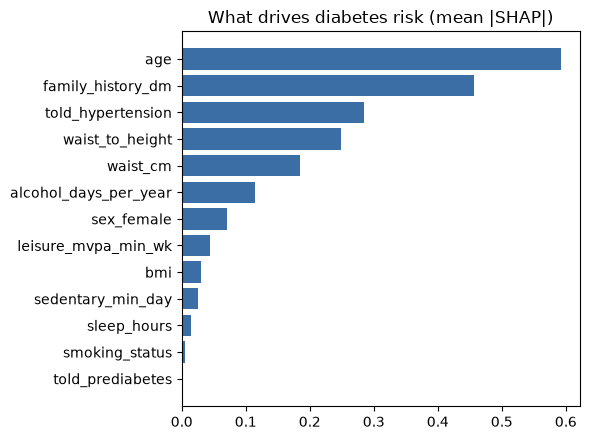

In [19]:
from sklearn.metrics import roc_curve

def idrs(df):
    """Indian Diabetes Risk Score (Mohan et al., MDRF). >= 60 = high risk.
    NHANES family history is yes/no, so 'yes' scores 10 (one parent)."""
    s = np.select([df.age >= 50, df.age >= 35], [30, 20], 0)
    male = df.sex_female == 0
    s = s + np.where(male, np.select([df.waist_cm >= 100, df.waist_cm >= 90], [20, 10], 0),
                           np.select([df.waist_cm >= 90, df.waist_cm >= 80], [20, 10], 0))
    s = s + np.select([df.leisure_mvpa_min_wk >= 150, df.leisure_mvpa_min_wk > 0], [0, 20], 30)
    s = s + np.where(df.family_history_dm == 1, 10, 0)
    return s.astype(float)

nk_va, nk_te, nk_ext = (va.ref_known_diabetes == 0).values, (te.ref_known_diabetes == 0).values, (ext.ref_known_diabetes == 0).values
u_va, u_te, u_ext = va.ref_undiagnosed_dm.values, te.ref_undiagnosed_dm.values, ext.ref_undiagnosed_dm.values

fpr, tpr, thr = roc_curve(u_va[nk_va], p_va[nk_va]); THRESHOLD = float(thr[np.argmax(tpr >= 0.80)])
fpr, tpr, thr = roc_curve(u_va[nk_va], predict_nofh(va)[nk_va]); THRESHOLD_NOFH = float(thr[np.argmax(tpr >= 0.80)])
print(f"Referral threshold: {THRESHOLD:.3f} (main)  |  {THRESHOLD_NOFH:.3f} (no family history)\n")

def screen(name, y, p, thr):
    flag = p >= thr
    print(f"{name:34s} AUROC {roc_auc_score(y, p):.3f} | refers {flag.mean():5.1%} | "
          f"catches {flag[y == 1].mean():5.1%} of {int(y.sum())} undiagnosed")

print("UNDIAGNOSED diabetes, among people not already diagnosed:")
screen("internal — our model",             u_te[nk_te],  p_te[nk_te],         THRESHOLD)
screen("internal — IDRS (≥60)",             u_te[nk_te],  idrs(te)[nk_te],      60)
screen("external — our model (no fam hx)", u_ext[nk_ext], p_ext_nofh[nk_ext],  THRESHOLD_NOFH)
screen("external — IDRS (no fam hx, ≥60)",  u_ext[nk_ext], idrs(ext)[nk_ext],   60)

contrib = model.predict(te[FEATURES], num_iteration=model.best_iteration, pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=FEATURES).sort_values()
plt.figure(figsize=(6, 4.5)); plt.barh(imp.index, imp.values, color="#3b6ea5")
plt.title("What drives diabetes risk (mean |SHAP|)"); plt.tight_layout(); plt.show()

In [20]:
import joblib
OUT = "/run/media/pravesh/New Volume/Promethius-26/models/diabetes"
os.makedirs(OUT, exist_ok=True)
for tag, m, c, feats, thr in [("dm_bundle", model, cal, FEATURES, THRESHOLD),
                              ("dm_bundle_nofh", model_nofh, cal_nofh, FEATURES_NOFH, THRESHOLD_NOFH)]:
    joblib.dump({"booster_str": m.model_to_string(num_iteration=m.best_iteration), "calibrator": c,
                 "features": feats, "threshold": thr,
                 "bands": [(0.0, 0.10, "low"), (0.10, 0.25, "moderate"), (0.25, 1.01, "high")]},
                os.path.join(OUT, f"{tag}.joblib"))
print("saved:", os.listdir(OUT))

saved: ['dm_bundle.joblib', 'dm_bundle_nofh.joblib']


## CVD 

In [26]:
DATA = "/run/media/pravesh/New Volume/Promethius-26/datasets"
import os, numpy as np, pandas as pd

cardio = pd.read_csv(os.path.join(DATA, "cardio_train.csv"), sep=";")
if cardio.shape[1] == 1:                       # file was saved with commas instead
    cardio = pd.read_csv(os.path.join(DATA, "train_cardio.csv"))
print("raw:", cardio.shape, list(cardio.columns))

c = pd.DataFrame({
    "age": cardio["age"] / 365.25,                        # days -> years
    "sex_female": (cardio["gender"] == 1).astype(float),  # 1 = women, 2 = men
    "height_cm": cardio["height"].astype(float),
    "weight_kg": cardio["weight"].astype(float),
    "sbp": cardio["ap_hi"].astype(float),
    "dbp": cardio["ap_lo"].astype(float),
    "cholesterol": cardio["cholesterol"],                 # 1 normal, 2 above, 3 well above
    "glucose": cardio["gluc"],                            # same scale
    "smoker": cardio["smoke"].astype(float),
    "alcohol": cardio["alco"].astype(float),
    "active": cardio["active"].astype(float),
    "cvd": cardio["cardio"].astype(int),
})
c["bmi"] = c.weight_kg / (c.height_cm / 100) ** 2

n0 = len(c)
ok = (c.height_cm.between(130, 210) & c.weight_kg.between(35, 200) & c.bmi.between(14, 60)
      & c.sbp.between(80, 240) & c.dbp.between(40, 150) & (c.sbp > c.dbp))
c = c[ok].drop_duplicates().reset_index(drop=True)
print(f"cleaned: {n0:,} -> {len(c):,} rows ({1 - len(c)/n0:.1%} removed as impossible)")
print(f"CVD rate {c.cvd.mean():.1%} | age {c.age.min():.0f}-{c.age.max():.0f} | "
      f"women {c.sex_female.mean():.0%}")
print(c.groupby(pd.cut(c.age, [29, 40, 50, 55, 60, 66]), observed=True).cvd.mean().round(3).rename("CVD rate by age"))
print(c.groupby(pd.cut(c.sbp, [0, 120, 130, 140, 160, 300]), observed=True).cvd.mean().round(3).rename("CVD rate by systolic BP"))

raw: (70000, 13) ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']
cleaned: 70,000 -> 68,511 rows (2.1% removed as impossible)
CVD rate 49.5% | age 30-65 | women 65%
age
(29, 40]    0.236
(40, 50]    0.375
(50, 55]    0.461
(55, 60]    0.563
(60, 66]    0.667
Name: CVD rate by age, dtype: float64
sbp
(0, 120]      0.316
(120, 130]    0.582
(130, 140]    0.811
(140, 160]    0.856
(160, 300]    0.866
Name: CVD rate by systolic BP, dtype: float64


train 41,106 | valid 13,702 | test 13,703
NO lab (village)           AUROC 0.789 | Brier 0.186 | @0.31: sens 86.3% spec 48.4%
WITH cholesterol+glucose   AUROC 0.802 | Brier 0.180 | @0.33: sens 85.9% spec 52.4%


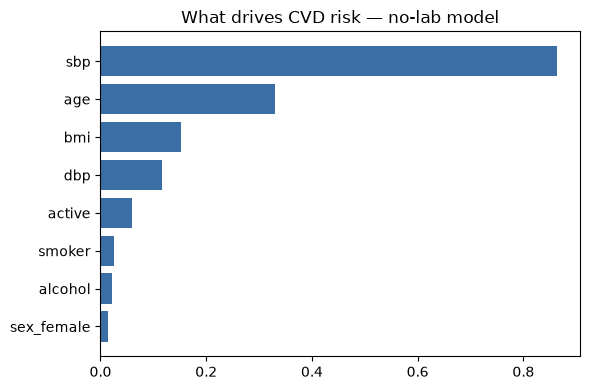

saved: ['cvd_lab_bundle.joblib', 'cvd_nolab_bundle.joblib']


In [27]:
import lightgbm as lgb, joblib, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve

SEED, TARGET = 42, "cvd"
NOLAB = ["age", "sex_female", "bmi", "sbp", "dbp", "smoker", "alcohol", "active"]   # village visit
LAB   = NOLAB + ["cholesterol", "glucose"]                                          # needs blood test
MONO  = {"age": 1, "bmi": 1, "sbp": 1, "dbp": 1, "cholesterol": 1, "glucose": 1}

tr, rest = train_test_split(c, test_size=0.4, stratify=c[TARGET], random_state=SEED)
va, te   = train_test_split(rest, test_size=0.5, stratify=rest[TARGET], random_state=SEED)
print(f"train {len(tr):,} | valid {len(va):,} | test {len(te):,}")

def fit(feats):
    params = dict(objective="binary", metric="auc", learning_rate=0.03, num_leaves=31,
                  min_child_samples=100, feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1,
                  lambda_l2=1.0, monotone_constraints=[MONO.get(f, 0) for f in feats],
                  monotone_constraints_method="advanced", verbose=-1, seed=SEED)
    dtr = lgb.Dataset(tr[feats], tr[TARGET]); dva = lgb.Dataset(va[feats], va[TARGET], reference=dtr)
    m = lgb.train(params, dtr, 3000, valid_sets=[dva], callbacks=[lgb.early_stopping(150, verbose=False)])
    raw = lambda df: m.predict(df[feats], num_iteration=m.best_iteration)
    cal = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(raw(va), va[TARGET])
    pred = lambda df: cal.predict(raw(df))
    fpr, tpr, thr = roc_curve(va[TARGET], pred(va))
    return m, cal, pred, float(thr[np.argmax(tpr >= 0.85)])       # threshold: catch 85%

m_nolab, cal_nolab, pred_nolab, thr_nolab = fit(NOLAB)
m_lab,   cal_lab,   pred_lab,   thr_lab   = fit(LAB)

y_te = te[TARGET].values
for name, p, t in [("NO lab (village)", pred_nolab(te), thr_nolab),
                   ("WITH cholesterol+glucose", pred_lab(te), thr_lab)]:
    flag = p >= t
    print(f"{name:26s} AUROC {roc_auc_score(y_te, p):.3f} | Brier {brier_score_loss(y_te, p):.3f} | "
          f"@{t:.2f}: sens {flag[y_te == 1].mean():.1%} spec {(~flag[y_te == 0]).mean():.1%}")

contrib = m_nolab.predict(te[NOLAB], num_iteration=m_nolab.best_iteration, pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=NOLAB).sort_values()
plt.figure(figsize=(6, 4)); plt.barh(imp.index, imp.values, color="#3b6ea5")
plt.title("What drives CVD risk — no-lab model"); plt.tight_layout(); plt.show()

OUT = "/run/media/pravesh/New Volume/Promethius-26/models/cvd"; os.makedirs(OUT, exist_ok=True)
for tag, m, cal_, feats, t in [("cvd_nolab_bundle", m_nolab, cal_nolab, NOLAB, thr_nolab),
                               ("cvd_lab_bundle",   m_lab,   cal_lab,   LAB,   thr_lab)]:
    joblib.dump({"booster_str": m.model_to_string(num_iteration=m.best_iteration), "calibrator": cal_,
                 "features": feats, "threshold": t,
                 "bands": [(0.0, 0.30, "low"), (0.30, 0.60, "moderate"), (0.60, 1.01, "high")]},
                os.path.join(OUT, f"{tag}.joblib"))
print("saved:", os.listdir(OUT))

In [28]:
pip install ucimlrepo

  Using cached certifi-2026.10.19-py3-none-any.whl.metadata (2.5 kB)
Using cached certifi-2026.10.19-py3-none-any.whl (136 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [ucimlrepo]
Note: you may need to restart the kernel to use updated packages.


In [29]:
DATA = "/run/media/pravesh/New Volume/Promethius-26/datasets"
import os, numpy as np, pandas as pd
path = os.path.join(DATA, "maternal_health_risk.csv")
if not os.path.exists(path):                       # first run: download from UCI
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=863)
    pd.concat([ds.data.features, ds.data.targets], axis=1).to_csv(path, index=False)
raw = pd.read_csv(path)
print("raw:", raw.shape, list(raw.columns))

FEATURES = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
LABELS = {"low risk": 0, "mid risk": 1, "high risk": 2}
df = raw.copy()
df["risk"] = df["RiskLevel"].str.strip().str.lower().map(LABELS)

n0 = len(df)
df = df.drop_duplicates(subset=FEATURES + ["risk"]).reset_index(drop=True)
print(f"duplicates removed: {n0} -> {len(df)} rows ({1 - len(df)/n0:.0%} were duplicates)")
conflict = df.duplicated(subset=FEATURES, keep=False).sum()
print(f"rows with identical vitals but different labels: {conflict}")
print("class balance:", df.risk.map({v: k for k, v in LABELS.items()}).value_counts().to_dict())
print(df.groupby("risk")[FEATURES].median().rename(index={0: "low", 1: "mid", 2: "high"}))

raw: (1014, 7) ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']
duplicates removed: 1014 -> 452 rows (55% were duplicates)
rows with identical vitals but different labels: 71
class balance: {'low risk': 234, 'high risk': 112, 'mid risk': 106}
       Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate
risk                                                          
low   22.0       100.0         75.0   7.2      98.0       70.0
mid   25.5       120.0         77.5   7.0      98.0       76.0
high  33.5       120.0         80.0  11.0      98.0       77.0


## Maternal

In [30]:
import lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, recall_score, roc_auc_score, confusion_matrix

X, y = df[FEATURES], df["risk"].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced", random_state=42),
    "LightGBM": lgb.LGBMClassifier(objective="multiclass", learning_rate=0.03, n_estimators=300, num_leaves=8,
                                   min_child_samples=10, class_weight="balanced", verbose=-1, random_state=42),
}
rows, probs = [], {}
for name, m in models.items():
    p = cross_val_predict(m, X, y, cv=cv, method="predict_proba"); probs[name] = p
    pred = p.argmax(1)
    rows.append({"model": name, "macro_F1": f1_score(y, pred, average="macro"),
                 "high_risk_recall": recall_score(y == 2, pred == 2),
                 "high_risk_AUROC": roc_auc_score(y == 2, p[:, 2]),
                 "accuracy": (pred == y).mean()})
res = pd.DataFrame(rows).sort_values(["high_risk_recall", "macro_F1"], ascending=False)
print(res.round(3).to_string(index=False))

best = res.iloc[0].model
print(f"\nConfusion matrix — {best} (rows = true low/mid/high, cols = predicted):")
print(confusion_matrix(y, probs[best].argmax(1)))

              model  macro_F1  high_risk_recall  high_risk_AUROC  accuracy
      Random Forest     0.611             0.795            0.930     0.664
           LightGBM     0.610             0.714            0.913     0.653
Logistic Regression     0.551             0.679            0.892     0.588

Confusion matrix — Random Forest (rows = true low/mid/high, cols = predicted):
[[179  42  13]
 [ 48  32  26]
 [  8  15  89]]


In [32]:
# ===== CELL 2b: binary "high risk vs not" — the decision an ASHA actually makes
yb = (df["risk"].values == 2).astype(int)
binary = {
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced", random_state=42),
    "LightGBM": lgb.LGBMClassifier(learning_rate=0.03, n_estimators=300, num_leaves=8, min_child_samples=10,
                                   class_weight="balanced", verbose=-1, random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
}
pb = {n: cross_val_predict(m, X, yb, cv=cv, method="predict_proba")[:, 1] for n, m in binary.items()}

print("HIGH RISK vs NOT (5-fold CV, out-of-fold):")
for n, p in pb.items():
    t = np.sort(p[yb == 1])[int(np.floor(0.10 * yb.sum()))]       # threshold catching ~90% of high-risk
    f = p >= t
    print(f"  {n:20s} AUROC {roc_auc_score(yb, p):.3f} | catch-90% threshold {t:.2f}: "
          f"recall {f[yb == 1].mean():.1%} | specificity {(~f[yb == 0]).mean():.1%} | "
          f"of those referred, truly high-risk {yb[f].mean():.1%}")

BEST_B = max(pb, key=lambda n: roc_auc_score(yb, pb[n]))
p = pb[BEST_B]
THRESHOLD_HIGH = float(np.sort(p[yb == 1])[int(np.floor(0.10 * yb.sum()))])
final_b = binary[BEST_B].fit(X, yb)
print(f"\nChosen: {BEST_B}, refer urgently if P(high) >= {THRESHOLD_HIGH:.2f}")

HIGH RISK vs NOT (5-fold CV, out-of-fold):
  Random Forest        AUROC 0.927 | catch-90% threshold 0.25: recall 90.2% | specificity 75.9% | of those referred, truly high-risk 55.2%
  LightGBM             AUROC 0.917 | catch-90% threshold 0.04: recall 90.2% | specificity 67.9% | of those referred, truly high-risk 48.1%
  Logistic Regression  AUROC 0.892 | catch-90% threshold 0.29: recall 90.2% | specificity 69.4% | of those referred, truly high-risk 49.3%

Chosen: Random Forest, refer urgently if P(high) >= 0.25


In [34]:
import joblib
final = models[best].fit(X, y)        # 3-class: advisory label

def maternal_risk(age, sbp, dbp, bs_mmol, temp_f, hr):
    x = pd.DataFrame([[age, sbp, dbp, bs_mmol, temp_f, hr]], columns=FEATURES)
    p3 = final.predict_proba(x)[0]
    p_high = float(final_b.predict_proba(x)[0, 1])
    level = ["low", "mid", "high"][int(p3.argmax())]
    rules = []
    if sbp >= 160 or dbp >= 110: rules.append("severe hypertension (≥160/110)")
    elif sbp >= 140 or dbp >= 90: rules.append("hypertension in pregnancy (≥140/90)")
    if bs_mmol >= 11.1:          rules.append("very high blood sugar (≥11.1 mmol/L)")
    if temp_f >= 100.4:          rules.append("fever (≥100.4 °F)")
    if hr >= 120:                rules.append("heart rate ≥120")
    if age < 18 or age >= 35:    rules.append("age risk (<18 or ≥35)")
    severe = any(r.startswith(("severe", "very high", "heart rate")) for r in rules)
    urgent = severe or p_high >= THRESHOLD_HIGH
    if urgent: level = "high"
    elif rules and level == "low": level = "mid"
    return {"level": level, "p_high": round(p_high, 3), "refer_urgently": urgent,
            "reason": "clinical danger sign" if severe else "model: high-risk pattern" if urgent else None,
            "flags": rules}

print(maternal_risk(24, 110, 70, 6.5, 98.0, 76))    # healthy
print(maternal_risk(36, 150, 95, 7.5, 98.0, 88))    # older, raised BP
print(maternal_risk(28, 165, 112, 6.0, 98.0, 80))   # severe BP -> always urgent

OUT = "/run/media/pravesh/New Volume/Promethius-26/models/maternal"; os.makedirs(OUT, exist_ok=True)
joblib.dump({"model_3class": final, "model_high": final_b, "threshold_high": THRESHOLD_HIGH,
             "features": FEATURES}, os.path.join(OUT, "maternal_bundle.joblib"))
print("saved:", os.listdir(OUT))

{'level': 'low', 'p_high': 0.025, 'refer_urgently': False, 'reason': None, 'flags': []}
{'level': 'high', 'p_high': 0.876, 'refer_urgently': True, 'reason': 'model: high-risk pattern', 'flags': ['hypertension in pregnancy (≥140/90)', 'age risk (<18 or ≥35)']}
{'level': 'high', 'p_high': 0.94, 'refer_urgently': True, 'reason': 'clinical danger sign', 'flags': ['severe hypertension (≥160/110)']}
saved: ['maternal_bundle.joblib']


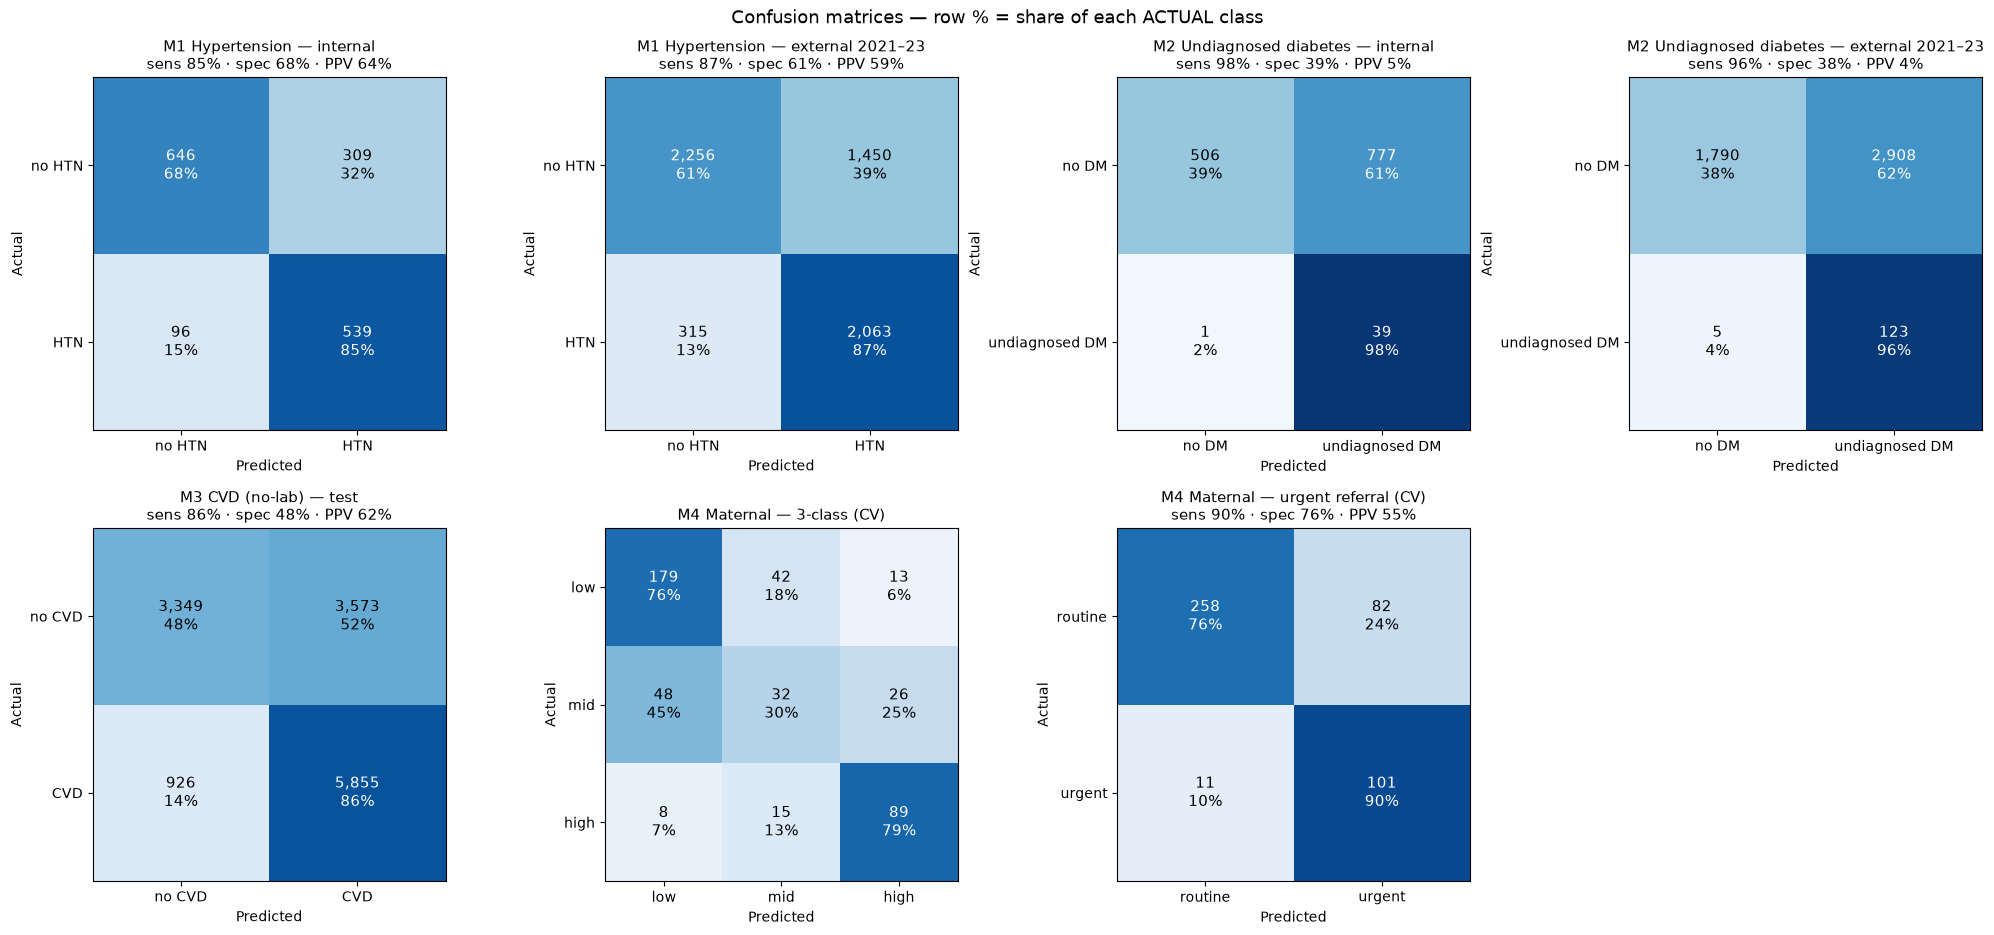

saved: /run/media/pravesh/New Volume/Promethius-26/models/confusion_matrices.png


In [40]:
# ===== CONFUSION MATRICES — all 4 models, rebuilt from saved bundles (independent of earlier cells)
BASE = "/run/media/pravesh/New Volume/Promethius-26"
import os, joblib, numpy as np, pandas as pd, lightgbm as lgb, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

D, M = os.path.join(BASE, "datasets"), os.path.join(BASE, "models")
SEED = 42

def bundle_predict(path):
    b = joblib.load(path)
    booster = lgb.Booster(model_str=b["booster_str"])
    return (lambda df: b["calibrator"].predict(booster.predict(df[b["features"]]))), b["threshold"]

def apply_limits(df, limits):
    df = df.copy()
    for c, (lo, hi) in limits.items():
        if c in df: df.loc[df[c].notna() & ~df[c].between(lo, hi), c] = np.nan
    return df

def split_test(df, target):
    _, rest = train_test_split(df, test_size=0.4, stratify=df[target], random_state=SEED)
    _, te = train_test_split(rest, test_size=0.5, stratify=rest[target], random_state=SEED)
    return te

LIM = {"age": (18, 80), "bmi": (13, 70), "waist_cm": (50, 180), "waist_to_height": (0.3, 1.0),
       "alcohol_days_per_year": (0, 365), "alcohol_drinks_per_day": (0, 15),
       "leisure_mvpa_min_wk": (0, 3000), "sedentary_min_day": (0, 1200), "sleep_hours": (3, 13)}
panels = []   # (title, y_true, y_pred, class_names)

# ---- Model 1: hypertension
pred, thr = bundle_predict(os.path.join(M, "hypertension", "htn_bundle.joblib"))
tr1 = apply_limits(pd.read_csv(os.path.join(D, "hypertension_train.csv")).drop_duplicates("seqn"), LIM).reset_index(drop=True)
ex1 = apply_limits(pd.read_csv(os.path.join(D, "hypertension_external.csv")).drop_duplicates("seqn"), LIM).reset_index(drop=True)
te1 = split_test(tr1, "htn")
panels += [("M1 Hypertension — internal", te1.htn.values, (pred(te1) >= thr).astype(int), ["no HTN", "HTN"]),
           ("M1 Hypertension — external 2021–23", ex1.htn.values, (pred(ex1) >= thr).astype(int), ["no HTN", "HTN"])]

# ---- Model 2: diabetes — scored on UNDIAGNOSED cases among people not already diagnosed
LIM2 = {**LIM, "age": (20, 80)}
pred2, thr2 = bundle_predict(os.path.join(M, "diabetes", "dm_bundle.joblib"))
pred2n, thr2n = bundle_predict(os.path.join(M, "diabetes", "dm_bundle_nofh.joblib"))
tr2 = apply_limits(pd.read_csv(os.path.join(D, "diabetes_train.csv")).drop_duplicates("seqn"), LIM2).reset_index(drop=True)
ex2 = apply_limits(pd.read_csv(os.path.join(D, "diabetes_external.csv")).drop_duplicates("seqn"), LIM2).reset_index(drop=True)
te2 = split_test(tr2, "dm")
for name, df, p, t in [("internal", te2, pred2, thr2), ("external 2021–23", ex2, pred2n, thr2n)]:
    nk = df[df.ref_known_diabetes == 0]
    panels.append((f"M2 Undiagnosed diabetes — {name}", nk.ref_undiagnosed_dm.values,
                   (p(nk) >= t).astype(int), ["no DM", "undiagnosed DM"]))

# ---- Model 3: CVD (cardio 70k, no-lab model)
raw = pd.read_csv(os.path.join(D, "cardio_train.csv"), sep=";")
if raw.shape[1] == 1: raw = pd.read_csv(os.path.join(D, "cardio_train.csv"))
c = pd.DataFrame({"age": raw.age / 365.25, "sex_female": (raw.gender == 1).astype(float),
                  "height_cm": raw.height.astype(float), "weight_kg": raw.weight.astype(float),
                  "sbp": raw.ap_hi.astype(float), "dbp": raw.ap_lo.astype(float),
                  "cholesterol": raw.cholesterol, "glucose": raw.gluc, "smoker": raw.smoke.astype(float),
                  "alcohol": raw.alco.astype(float), "active": raw.active.astype(float), "cvd": raw.cardio.astype(int)})
c["bmi"] = c.weight_kg / (c.height_cm / 100) ** 2
c = c[c.height_cm.between(130, 210) & c.weight_kg.between(35, 200) & c.bmi.between(14, 60)
      & c.sbp.between(80, 240) & c.dbp.between(40, 150) & (c.sbp > c.dbp)].drop_duplicates().reset_index(drop=True)
pred3, thr3 = bundle_predict(os.path.join(M, "cvd", "cvd_nolab_bundle.joblib"))
te3 = split_test(c, "cvd")
panels.append(("M3 CVD (no-lab) — test", te3.cvd.values, (pred3(te3) >= thr3).astype(int), ["no CVD", "CVD"]))

# ---- Model 4: maternal — out-of-fold (5-fold CV) because the saved model was trained on all rows
F4 = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]
m4 = pd.read_csv(os.path.join(D, "maternal_health_risk.csv"))
m4["risk"] = m4.RiskLevel.str.strip().str.lower().map({"low risk": 0, "mid risk": 1, "high risk": 2})
m4 = m4.drop_duplicates(subset=F4 + ["risk"]).reset_index(drop=True)
b4 = joblib.load(os.path.join(M, "maternal", "maternal_bundle.joblib"))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced", random_state=42)
p3 = cross_val_predict(rf(), m4[F4], m4.risk, cv=cv, method="predict_proba")
yb = (m4.risk.values == 2).astype(int)
pb = cross_val_predict(rf(), m4[F4], yb, cv=cv, method="predict_proba")[:, 1]
thr4 = b4.get("threshold_high", 0.5)
panels += [("M4 Maternal — 3-class (CV)", m4.risk.values, p3.argmax(1), ["low", "mid", "high"]),
           ("M4 Maternal — urgent referral (CV)", yb, (pb >= thr4).astype(int), ["routine", "urgent"])]

# ---- plot
fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for ax, (title, y, yp, names) in zip(axes.flat, panels):
    k = len(names)
    cm = confusion_matrix(y, yp, labels=range(k))
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{cm[i, j]:,}\n{pct[i, j]:.0%}", ha="center", va="center",
                    color="white" if pct[i, j] > 0.55 else "black", fontsize=11)
    ax.set_xticks(range(k), names); ax.set_yticks(range(k), names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    if k == 2:
        tn, fp, fn, tp = cm.ravel()
        title += f"\nsens {tp/max(tp+fn,1):.0%} · spec {tn/max(tn+fp,1):.0%} · PPV {tp/max(tp+fp,1):.0%}"
    ax.set_title(title, fontsize=10.5)
for ax in axes.flat[len(panels):]: ax.axis("off")
plt.suptitle("Confusion matrices — row % = share of each ACTUAL class", fontsize=13)
plt.tight_layout(); plt.show()
fig.savefig(os.path.join(M, "confusion_matrices.png"), dpi=150, bbox_inches="tight")
print("saved:", os.path.join(M, "confusion_matrices.png"))

In [41]:
# ===== FIX M2 THRESHOLD — choose by referral rate (stable), then re-save
BASE = "/run/media/pravesh/New Volume/Promethius-26"
import os, joblib, numpy as np, pandas as pd, lightgbm as lgb
from sklearn.model_selection import train_test_split

D, M = os.path.join(BASE, "datasets"), os.path.join(BASE, "models", "diabetes")
LIM = {"age": (20, 80), "bmi": (13, 70), "waist_cm": (50, 180), "waist_to_height": (0.3, 1.0),
       "alcohol_days_per_year": (0, 365), "leisure_mvpa_min_wk": (0, 3000),
       "sedentary_min_day": (0, 1200), "sleep_hours": (3, 13)}
def prep(f):
    df = pd.read_csv(os.path.join(D, f)).drop_duplicates("seqn").reset_index(drop=True)
    for c, (lo, hi) in LIM.items():
        df.loc[df[c].notna() & ~df[c].between(lo, hi), c] = np.nan
    return df
tr, ex = prep("diabetes_train.csv"), prep("diabetes_external.csv")
_, rest = train_test_split(tr, test_size=0.4, stratify=tr.dm, random_state=42)
va, te = train_test_split(rest, test_size=0.5, stratify=rest.dm, random_state=42)

def load(name):
    b = joblib.load(os.path.join(M, name)); bst = lgb.Booster(model_str=b["booster_str"])
    return b, (lambda df: b["calibrator"].predict(bst.predict(df[b["features"]])))

b_main, p_main = load("dm_bundle.joblib")
b_nofh, p_nofh = load("dm_bundle_nofh.joblib")
nk = lambda df: df[df.ref_known_diabetes == 0]          # people the app actually screens

def stats(df, p, t):
    d = nk(df); s = p(d); f = s >= t; u = d.ref_undiagnosed_dm.values == 1
    return f.mean(), f[u].mean(), u[f].mean() if f.any() else 0, (~f[~u]).mean()

print(f"{'refer top':>9} | {'internal: refers  catches  PPV  spec':^40} | {'external (no fam hx): refers  catches  PPV':^44}")
for rate in (0.15, 0.20, 0.25, 0.30, 0.35, 0.40):
    t_m = float(np.quantile(p_main(nk(va)), 1 - rate))     # threshold from VALID only
    t_n = float(np.quantile(p_nofh(nk(va)), 1 - rate))
    r1, c1, v1, s1 = stats(te, p_main, t_m); r2, c2, v2, _ = stats(ex, p_nofh, t_n)
    print(f"{rate:>9.0%} | {r1:12.0%} {c1:8.0%} {v1:6.1%} {s1:5.0%} | {r2:20.0%} {c2:8.0%} {v2:6.1%}")

refer top |   internal: refers  catches  PPV  spec   |  external (no fam hx): refers  catches  PPV 
      15% |          15%      40%   8.0%   86% |                  19%      49%   7.0%
      20% |          30%      70%   7.0%   71% |                  24%      57%   6.3%
      25% |          30%      70%   7.0%   71% |                  29%      62%   5.6%
      30% |          33%      75%   6.9%   68% |                  53%      87%   4.4%
      35% |          41%      88%   6.4%   60% |                  53%      87%   4.4%
      40% |          42%      88%   6.4%   60% |                  53%      87%   4.4%


In [42]:
REFER_RATE = 0.25          # <- your chosen row
b_main["threshold"] = float(np.quantile(p_main(nk(va)), 1 - REFER_RATE))
b_nofh["threshold"] = float(np.quantile(p_nofh(nk(va)), 1 - REFER_RATE))
b_main["refer_rate"] = b_nofh["refer_rate"] = REFER_RATE
joblib.dump(b_main, os.path.join(M, "dm_bundle.joblib"))
joblib.dump(b_nofh, os.path.join(M, "dm_bundle_nofh.joblib"))
print(f"saved: refer top {REFER_RATE:.0%} | thresholds {b_main['threshold']:.3f} (main), {b_nofh['threshold']:.3f} (no fam hx)")

saved: refer top 25% | thresholds 0.271 (main), 0.241 (no fam hx)


In [43]:
# ===== FINAL METRICS TABLE — run AFTER the confusion-matrix cell
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, balanced_accuracy_score, classification_report)

def row(model, test, y, yp, prob=None):
    y, yp = np.asarray(y), np.asarray(yp)
    tn = ((yp == 0) & (y == 0)).sum(); fp = ((yp == 1) & (y == 0)).sum()
    return {"Model": model, "Test set": test, "n": len(y), "Positives": int(y.sum()),
            "Accuracy": accuracy_score(y, yp),
            "Balanced acc.": balanced_accuracy_score(y, yp),
            "Precision (PPV)": precision_score(y, yp, zero_division=0),
            "Recall (sensitivity)": recall_score(y, yp, zero_division=0),
            "Specificity": tn / max(tn + fp, 1),
            "F1": f1_score(y, yp, zero_division=0),
            "AUROC": roc_auc_score(y, prob) if prob is not None else np.nan}

rows = []
# M1 hypertension
p = pred(te1);  rows.append(row("M1 Hypertension", "internal 2017–20", te1.htn, p >= thr, p))
p = pred(ex1);  rows.append(row("M1 Hypertension", "external 2021–23", ex1.htn, p >= thr, p))
# M2 diabetes (undiagnosed, among not-yet-diagnosed)
for name, df, pf, t in [("internal 2017–20", te2, pred2, thr2), ("external 2021–23", ex2, pred2n, thr2n)]:
    nk = df[df.ref_known_diabetes == 0]; p = pf(nk)
    rows.append(row("M2 Undiagnosed diabetes", name, nk.ref_undiagnosed_dm, p >= t, p))
# M3 CVD
p = pred3(te3); rows.append(row("M3 CVD (no-lab)", "held-out test", te3.cvd, p >= thr3, p))
# M4 maternal — urgent referral
rows.append(row("M4 Maternal (urgent)", "5-fold CV", yb, pb >= thr4, pb))

table = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print(table.round(3).to_string(index=False))

print("\nM4 Maternal 3-class (5-fold CV):")
print(classification_report(m4.risk, p3.argmax(1), target_names=["low", "mid", "high"], digits=3))

table.round(3).to_csv(os.path.join(M, "final_metrics.csv"), index=False)
print("saved:", os.path.join(M, "final_metrics.csv"))

                  Model         Test set     n  Positives  Accuracy  Balanced acc.  Precision (PPV)  Recall (sensitivity)  Specificity    F1  AUROC
        M1 Hypertension internal 2017–20  1590        635     0.745          0.763            0.636                 0.849        0.676 0.727  0.841
        M1 Hypertension external 2021–23  6084       2378     0.710          0.738            0.587                 0.868        0.609 0.700  0.816
M2 Undiagnosed diabetes internal 2017–20  1323         40     0.412          0.685            0.048                 0.975        0.394 0.091  0.786
M2 Undiagnosed diabetes external 2021–23  4826        128     0.396          0.671            0.041                 0.961        0.381 0.078  0.753
        M3 CVD (no-lab)    held-out test 13703       6781     0.672          0.674            0.621                 0.863        0.484 0.722  0.789
   M4 Maternal (urgent)        5-fold CV   452        112     0.794          0.830            0.552             

## Heart PPG

In [36]:
pip install wfdb

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (46 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 216.4 kB/s  0:00:08 eta 0:00:01
Using cached attrs-26.1.0-py3-none-any.whl (67 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached charset_normalizer-3.5.2-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (255 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 355.0 kB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [wfdb]2m15/17 [aiohttp]e]
Note: you may need to res

In [ ]:
"""HA-01 · Model 5 — Heart rate from phone camera (PPG) + signal-quality check
Data: BUT PPG v2.0.0 (PhysioNet, open access)
  Download zip: https://physionet.org/content/butppg/get-zip/2.0.0/   (87 MB)
  Unzip into datasets/butppg so that datasets/butppg/100001/100001_PPG.hea exists
  pip install wfdb scipy lightgbm joblib
Run cell by cell in VS Code (each "# %%" is a cell) or paste into the notebook.
"""

# %%
# ===== CELL 1: load BUT PPG (WFDB) + annotations
# pip install wfdb scipy
ROOT = "/run/media/pravesh/New Volume/Promethius-26/datasets/butppg"     # folder containing 100001/, 100002/, ..., quality-hr-ann.csv
import os, glob, numpy as np, pandas as pd, wfdb
from scipy.signal import butter, filtfilt, find_peaks, welch
from scipy.stats import skew, kurtosis

ann = pd.read_csv(os.path.join(ROOT, "quality-hr-ann.csv"), header=None)
if not str(ann.iloc[0, 0]).strip().isdigit():          # file has a header row
    ann = pd.read_csv(os.path.join(ROOT, "quality-hr-ann.csv"))
ann = ann.iloc[:, :3]; ann.columns = ["id", "quality", "hr_ref"]
ann["id"] = ann["id"].astype(str).str.strip().str.zfill(6)
ann["subject"] = ann["id"].str[:3]

def load_ppg(rec_id):
    """Return (signal 1-D, fs). Uses the RED channel if multi-channel (best for fingertip)."""
    hea = glob.glob(os.path.join(ROOT, rec_id, f"{rec_id}_PPG.hea"))
    if not hea:
        return None, None
    r = wfdb.rdrecord(hea[0][:-4])
    sig = r.p_signal if r.p_signal is not None else r.d_signal.astype(float)
    names = [n.upper() for n in (r.sig_name or [])]
    ch = names.index("R") if "R" in names else 0
    return sig[:, ch].astype(float), r.fs

sigs, fss = {}, {}
for rid in ann["id"]:
    s, fs = load_ppg(rid)
    if s is not None:
        sigs[rid], fss[rid] = s, fs
ann = ann[ann["id"].isin(sigs)].reset_index(drop=True)
print(f"records loaded: {len(ann):,} | subjects: {ann.subject.nunique()} | "
      f"good quality: {ann.quality.mean():.1%} | fs: {set(fss.values())} | "
      f"length: {np.median([len(s) for s in sigs.values()]):.0f} samples")

# %%
# ===== CELL 2: heart-rate algorithm (signal processing) + validation vs ECG reference
LO, HI = 0.7, 3.5          # 42–210 bpm

def bandpass(x, fs):
    b, a = butter(3, [LO / (fs / 2), HI / (fs / 2)], btype="band")
    return filtfilt(b, a, x - np.mean(x))

def estimate_hr(x, fs):
    """Two independent estimates: spectral peak and peak-to-peak interval. Returns dict."""
    y = bandpass(x, fs)
    # 1) spectrum (zero-padded Welch for finer resolution)
    f, P = welch(y, fs=fs, nperseg=min(len(y), 256), nfft=2048)
    band = (f >= LO) & (f <= HI)
    hr_fft = 60 * f[band][np.argmax(P[band])]
    # 2) peaks — PPG pulses point DOWN in reflectance video, so try both polarities
    best = None
    for sgn in (1, -1):
        pk, _ = find_peaks(sgn * y, distance=int(fs * 60 / 210), prominence=np.std(y) * 0.3)
        if len(pk) >= 3:
            ibi = np.diff(pk) / fs
            cand = (60 / np.median(ibi), np.std(ibi) / np.mean(ibi))
            if best is None or cand[1] < best[1]:
                best = cand
    hr_peak, ibi_cv = best if best else (np.nan, np.nan)
    return {"hr_fft": hr_fft, "hr_peak": hr_peak, "ibi_cv": ibi_cv, "filtered": y, "f": f, "P": P}

est = {rid: estimate_hr(sigs[rid], fss[rid]) for rid in ann["id"]}
ann["hr_fft"] = ann["id"].map(lambda r: est[r]["hr_fft"])
ann["hr_peak"] = ann["id"].map(lambda r: est[r]["hr_peak"])
ann["hr_est"] = ann["hr_fft"]

for q, name in [(1, "GOOD-quality"), (0, "POOR-quality")]:
    d = ann[(ann.quality == q) & ann.hr_ref.notna()]
    err = (d.hr_est - d.hr_ref).abs()
    print(f"{name:13s} n={len(d):4d} | MAE {err.mean():5.1f} bpm | within ±5 bpm: {(err <= 5).mean():.1%} "
          f"| within ±10: {(err <= 10).mean():.1%}")

# %%
# ===== CELL 3: signal-quality features + classifier (split BY PERSON)
import lightgbm as lgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

def quality_features(x, fs, e):
    y, f, P = e["filtered"], e["f"], e["P"]
    band = (f >= LO) & (f <= HI)
    f0 = f[band][np.argmax(P[band])]
    near = lambda c, w=0.15: (np.abs(f - c) <= w)
    sig_pow = P[near(f0)].sum() + P[near(2 * f0)].sum()
    snr = sig_pow / max(P[band].sum() - P[near(f0) & band].sum(), 1e-12)
    ac = np.correlate(y, y, "full")[len(y) - 1:]; ac /= ac[0] if ac[0] else 1
    lag_lo, lag_hi = int(fs * 60 / 210), min(int(fs * 60 / 40), len(ac) - 1)
    raw = x - np.median(x)
    return {
        "snr": snr,
        "spectral_peak_share": P[near(f0)].sum() / max(P[band].sum(), 1e-12),
        "autocorr_peak": ac[lag_lo:lag_hi].max() if lag_hi > lag_lo else np.nan,
        "hr_fft_vs_peak_diff": abs(e["hr_fft"] - e["hr_peak"]) if np.isfinite(e["hr_peak"]) else 60.0,
        "ibi_cv": e["ibi_cv"] if np.isfinite(e["ibi_cv"]) else 1.0,
        "skewness": skew(y), "kurtosis": kurtosis(y),
        "perfusion": np.std(y) / (abs(np.mean(x)) + 1e-9),
        "raw_range_ratio": (np.percentile(raw, 99) - np.percentile(raw, 1)) / (np.std(y) * 4 + 1e-9),
        "zero_cross_rate": np.mean(np.diff(np.sign(y)) != 0) * fs,
        "hr_fft": e["hr_fft"],
    }

QF = pd.DataFrame([quality_features(sigs[r], fss[r], est[r]) for r in ann["id"]])
QFEAT = list(QF.columns)
X, yq, groups = QF.values, ann["quality"].values, ann["subject"].values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)    # no person in both train & test
clf = lgb.LGBMClassifier(learning_rate=0.03, n_estimators=400, num_leaves=15, min_child_samples=20,
                         class_weight="balanced", verbose=-1, random_state=42)
p = cross_val_predict(clf, QF, yq, cv=cv, groups=groups, method="predict_proba")[:, 1]
print(f"Quality classifier (person-level CV): AUROC {roc_auc_score(yq, p):.3f}")

# operating point: accept a reading only if we're confident it's good
for t in (0.5, 0.6, 0.7, 0.8):
    acc = p >= t
    d = ann[acc & ann.hr_ref.notna()]
    err = (d.hr_est - d.hr_ref).abs()
    print(f"  accept if P(good) >= {t:.1f}: accepts {acc.mean():5.1%} of readings | "
          f"{yq[acc].mean() if acc.any() else 0:.1%} truly good | HR MAE on accepted {err.mean():.1f} bpm")

# %%
# ===== CELL 4: final fit + one function for the app + save
import joblib
QTHRESH = 0.6                                 # <- pick from the table above
clf.fit(QF, yq)

def measure_heart_rate(signal, fs):
    """Input: raw red-channel brightness per video frame (fingertip on camera+flash)."""
    x = np.asarray(signal, float)
    if len(x) < fs * 8:
        return {"ok": False, "message": "Recording too short — keep finger on camera for 10 s"}
    e = estimate_hr(x, fs)
    q = float(clf.predict_proba(pd.DataFrame([quality_features(x, fs, e)])[QFEAT])[0, 1])
    if q < QTHRESH:
        return {"ok": False, "quality": round(q, 2),
                "message": "Signal unclear — press finger gently over camera and flash, hold still"}
    return {"ok": True, "heart_rate_bpm": round(float(e["hr_fft"])), "quality": round(q, 2)}

r0 = ann["id"].iloc[0]
print(measure_heart_rate(sigs[r0], fss[r0]), "| reference:", ann.hr_ref.iloc[0])

OUT = "/run/media/pravesh/New Volume/Promethius-26/models/ppg"; os.makedirs(OUT, exist_ok=True)
joblib.dump({"quality_model": clf, "features": QFEAT, "threshold": QTHRESH, "band_hz": (LO, HI)},
            os.path.join(OUT, "ppg_quality_bundle.joblib"))
print("saved:", os.listdir(OUT))